# 04 - Train the Farm A LSTM autoencoder

This notebook trains the model using normal training windows. It checks learning with validation data and chooses an alert threshold from that validation data. It does **not** calculate final prediction metrics; that is done in `05_evaluation.ipynb`.

Run `03_feature_engineering.ipynb` first, then run this notebook from top to bottom. The final cell saves the model and the files needed to reproduce training.


## The three data parts

- **Training:** teaches the model normal sensor patterns.
- **Validation:** checks learning and sets the alert threshold.
- **Prediction:** held aside for final evaluation in notebook 05.

Notebook 03 assigns each turbine timestamp to only one part. This notebook checks that no timestamp is shared between parts before training starts.


In [30]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from IPython.display import display

cwd = Path.cwd()
PROJECT_ROOT = next(
    (p for p in (cwd, *cwd.parents)
     if (p / "data/processed/farm_a/features/farm_a_lstm_windows.npz").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run 03_feature_engineering.ipynb first")

FEATURE_DIR = PROJECT_ROOT / "data/processed/farm_a/features"
WINDOW_FILE = FEATURE_DIR / "farm_a_lstm_windows.npz"
WINDOW_META_FILE = FEATURE_DIR / "window_metadata.csv"
sys.path.insert(0, str(PROJECT_ROOT))
from src.model import NormalLSTMAutoencoder

RANDOM_SEED = 42
EPOCHS = 8
BATCH_SIZE = 256
LEARNING_RATE = 0.001
HIDDEN_SIZE = 64
THRESHOLD_QUANTILE = 0.90
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Project:", PROJECT_ROOT)
print("Compute device:", DEVICE)
print("Prepared windows:", WINDOW_FILE)


Project: c:\Users\mohamad\Desktop\Predictive-Maintenance
Compute device: cpu
Prepared windows: c:\Users\mohamad\Desktop\Predictive-Maintenance\data\processed\farm_a\features\farm_a_lstm_windows.npz


## 1. Load training and validation data and check the split

We do not load the prediction sensor windows here. That keeps the final evaluation separate from model training.


In [31]:
bundle = np.load(WINDOW_FILE)
X_train_raw = bundle["X_train"].astype(np.float32)
X_validation_raw = bundle["X_validation"].astype(np.float32)
FEATURE_NAMES = bundle["feature_names"].astype(str).tolist()
WINDOW_SIZE = int(bundle["window_size"])
window_meta = pd.read_csv(WINDOW_META_FILE, parse_dates=["start_time", "end_time"])

for name, array in [("train", X_train_raw), ("validation", X_validation_raw)]:
    if array.ndim != 3 or array.shape[1] != WINDOW_SIZE or array.shape[2] != len(FEATURE_NAMES):
        raise ValueError(f"Unexpected shape for {name}: {array.shape}")
    if not np.isfinite(array).all():
        raise ValueError(f"Non-finite sensor values in {name} windows")
    rows = window_meta.loc[window_meta.partition.eq(name)].sort_values("window_index")
    if len(rows) != len(array) or not np.array_equal(rows.window_index.to_numpy(), np.arange(len(array))):
        raise ValueError(f"Metadata does not align with {name} array")

prediction_rows = window_meta.loc[window_meta.partition.eq("prediction")].sort_values("window_index")
if not np.array_equal(prediction_rows.window_index.to_numpy(), np.arange(len(prediction_rows))):
    raise ValueError("Prediction metadata window indices are not in order")

# Check the timestamps assigned to all three partitions without loading prediction sensor values.
def timestamp_keys(rows):
    keys = set()
    for row in rows.itertuples(index=False):
        times = pd.date_range(row.start_time, periods=WINDOW_SIZE, freq="10min")
        if times[-1] != row.end_time:
            raise ValueError("Unexpected spacing inside a saved window")
        keys.update((str(row.turbine_id), t) for t in times)
    return keys

keys = {
    name: timestamp_keys(window_meta.loc[window_meta.partition.eq(name)])
    for name in ["train", "validation", "prediction"]
}
for left, right in [("train", "validation"), ("train", "prediction"), ("validation", "prediction")]:
    shared = keys[left] & keys[right]
    print(f"Shared turbine timestamps in {left} and {right}: {len(shared)}")
    if shared:
        raise ValueError(f"Timestamp leakage remains between {left} and {right}; stop and fix notebook 03")

print("Training windows:", len(X_train_raw))
print("Validation windows:", len(X_validation_raw))
print("Prediction windows held for notebook 05:", len(prediction_rows))
print("Sensor features:", len(FEATURE_NAMES), "| window length:", WINDOW_SIZE)


Shared turbine timestamps in train and validation: 0
Shared turbine timestamps in train and prediction: 0
Shared turbine timestamps in validation and prediction: 0
Training windows: 7094
Validation windows: 1046
Prediction windows held for notebook 05: 441
Sensor features: 45 | window length: 12


## 2. Scale values using training data only

Sensors can have different numeric ranges. The scaler learns from training windows only, then applies that same transformation to validation data.


In [32]:
n_features = X_train_raw.shape[2]
scaler = StandardScaler()
scaler.fit(X_train_raw.reshape(-1, n_features))

def scale_windows(x):
    rows = x.reshape(-1, n_features)
    return scaler.transform(rows).reshape(x.shape).astype(np.float32)

X_train = scale_windows(X_train_raw)
X_validation = scale_windows(X_validation_raw)
print("Scaled training shape:", X_train.shape)
print("Scaled validation shape:", X_validation.shape)
print("Scaler fit rows:", X_train_raw.shape[0] * X_train_raw.shape[1], "(training only)")


Scaled training shape: (7094, 12, 45)
Scaled validation shape: (1046, 12, 45)
Scaler fit rows: 85128 (training only)


## 3. Train the model

The model learns from normal training windows. Validation windows are used only to monitor learning.


Epoch 1/8: training MSE=0.723779; validation MSE=0.630905
Epoch 2/8: training MSE=0.427284; validation MSE=0.419271
Epoch 3/8: training MSE=0.328992; validation MSE=0.319312
Epoch 4/8: training MSE=0.282678; validation MSE=0.272530
Epoch 5/8: training MSE=0.247902; validation MSE=0.235129
Epoch 6/8: training MSE=0.221295; validation MSE=0.212761
Epoch 7/8: training MSE=0.202089; validation MSE=0.194930
Epoch 8/8: training MSE=0.186370; validation MSE=0.181862


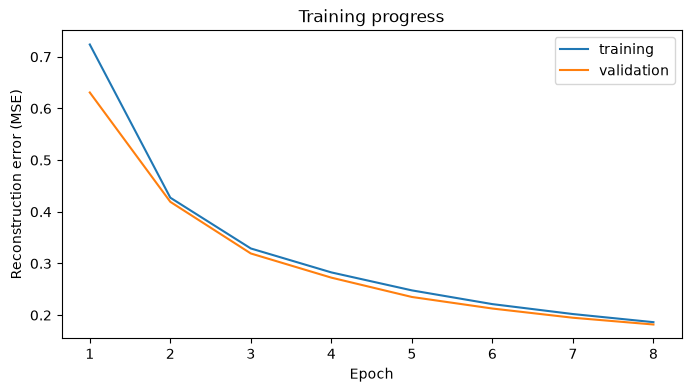

In [33]:
model = NormalLSTMAutoencoder(n_features=len(FEATURE_NAMES), hidden_size=HIDDEN_SIZE).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train)), batch_size=BATCH_SIZE, shuffle=True
)
validation_tensor = torch.from_numpy(X_validation).to(DEVICE)
train_history = []
validation_history = []

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []
    for (batch,) in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        reconstruction = model(batch)
        loss = ((reconstruction - batch) ** 2).mean()
        loss.backward()
        optimizer.step()
        batch_losses.append(float(loss.item()))

    model.eval()
    with torch.no_grad():
        val_error = ((model(validation_tensor) - validation_tensor) ** 2).mean(dim=(1, 2))
        val_loss = float(val_error.mean().item())
    train_loss = float(np.mean(batch_losses))
    train_history.append(train_loss)
    validation_history.append(val_loss)
    print(f"Epoch {epoch + 1}/{EPOCHS}: training MSE={train_loss:.6f}; validation MSE={val_loss:.6f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_history, label="training")
plt.plot(range(1, EPOCHS + 1), validation_history, label="validation")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction error (MSE)")
plt.title("Training progress")
plt.legend()
plt.show()


## 4. Compare alert thresholds using validation data only

A lower threshold raises more alerts. We compare four choices using normal validation windows only. For this experiment, we use the 90th-percentile threshold: about 10 out of 100 normal validation windows may be flagged. This more sensitive setting may catch more anomalies, but can also raise more false alarms. Notebook 05 will test it on the separate prediction data.


Threshold choices measured on normal validation data:


,validation_percentile,threshold,validation_windows_flagged_percent
0,0.900,0.3291,9.8470
1,0.950,0.4057,4.9713
2,0.975,0.5311,2.4857
3,0.990,0.6664,1.0516


Selected threshold: validation 90.0% percentile = 0.329109
Normal validation windows flagged: 9.8%


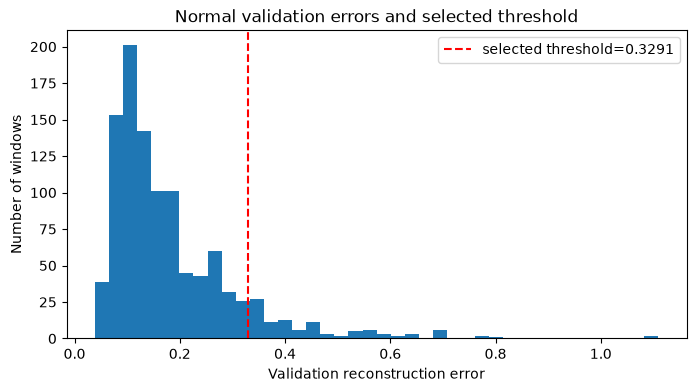

In [34]:
model.eval()
with torch.no_grad():
    validation_scores = ((model(validation_tensor) - validation_tensor) ** 2).mean(dim=(1, 2)).cpu().numpy()

CANDIDATE_QUANTILES = [0.90, 0.95, 0.975, 0.99]
threshold_comparison = pd.DataFrame([
    {
        "validation_percentile": q,
        "threshold": float(np.quantile(validation_scores, q)),
        "validation_windows_flagged_percent": float(
            (validation_scores > np.quantile(validation_scores, q)).mean() * 100
        ),
    }
    for q in CANDIDATE_QUANTILES
])
print("Threshold choices measured on normal validation data:")
display(threshold_comparison.round(4))

# Choose the 90th percentile before looking at prediction results.
threshold = float(np.quantile(validation_scores, THRESHOLD_QUANTILE))
validation_alert_rate = float((validation_scores > threshold).mean())
print(f"Selected threshold: validation {THRESHOLD_QUANTILE:.1%} percentile = {threshold:.6f}")
print(f"Normal validation windows flagged: {validation_alert_rate:.1%}")

plt.figure(figsize=(8, 4))
plt.hist(validation_scores, bins=40)
plt.axvline(threshold, color="red", linestyle="--", label=f"selected threshold={threshold:.4f}")
plt.xlabel("Validation reconstruction error")
plt.ylabel("Number of windows")
plt.title("Normal validation errors and selected threshold")
plt.legend()
plt.show()


## 5. Save training files

Run this cell after training. It saves the model, training-only scaler, learning history, and settings under `models/farm_a/`. Notebook 05 uses the saved model and scaler for final evaluation.


In [35]:
MODEL_DIR = PROJECT_ROOT / "models" / "farm_a"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "lstm_autoencoder.pt"
scaler_path = MODEL_DIR / "scaler.joblib"
history_path = MODEL_DIR / "training_history.csv"
config_path = MODEL_DIR / "training_config.json"
threshold_table_path = MODEL_DIR / "validation_threshold_comparison.csv"

checkpoint = {
    "state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
    "n_features": len(FEATURE_NAMES),
    "feature_names": FEATURE_NAMES,
    "window_size": WINDOW_SIZE,
    "hidden_size": HIDDEN_SIZE,
    "threshold": threshold,
    "threshold_quantile": THRESHOLD_QUANTILE,
        "validation_alert_rate": validation_alert_rate,
}
torch.save(checkpoint, model_path)
joblib.dump(scaler, scaler_path)
pd.DataFrame({
    "epoch": np.arange(1, EPOCHS + 1),
    "training_mse": train_history,
    "validation_mse": validation_history,
}).to_csv(history_path, index=False)
threshold_comparison.to_csv(threshold_table_path, index=False)
with config_path.open("w", encoding="utf-8") as f:
    json.dump({
        "random_seed": RANDOM_SEED,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "hidden_size": HIDDEN_SIZE,
        "window_size": WINDOW_SIZE,
        "feature_names": FEATURE_NAMES,
        "threshold_quantile": THRESHOLD_QUANTILE,
        "validation_alert_rate": validation_alert_rate,
        "threshold": threshold,
        "training_windows": int(len(X_train)),
        "validation_windows": int(len(X_validation)),
        "device": str(DEVICE),
    }, f, indent=2)

print("Saved model:", model_path)
print("Saved training-only scaler:", scaler_path)
print("Saved learning history:", history_path)
print("Saved training settings:", config_path)
print("Saved threshold comparison:", threshold_table_path)


Saved model: c:\Users\mohamad\Desktop\Predictive-Maintenance\models\farm_a\lstm_autoencoder.pt
Saved training-only scaler: c:\Users\mohamad\Desktop\Predictive-Maintenance\models\farm_a\scaler.joblib
Saved learning history: c:\Users\mohamad\Desktop\Predictive-Maintenance\models\farm_a\training_history.csv
Saved training settings: c:\Users\mohamad\Desktop\Predictive-Maintenance\models\farm_a\training_config.json
Saved threshold comparison: c:\Users\mohamad\Desktop\Predictive-Maintenance\models\farm_a\validation_threshold_comparison.csv


## Next

After this notebook finishes, run `05_evaluation.ipynb` to see how the 90th-percentile threshold performs on the held-out prediction data. Do not choose a threshold by trying different values on the prediction results. Save the notebook after running if you want its visible outputs kept in the notebook file.
